## Importación de librerías necesarias

En Windows, instala CBC una vez en el entorno de este kernel con `%pip install "pulp[cbc]"`.

In [16]:
import pandas as pd
from pathlib import Path
import time
import pulp
import matplotlib.pyplot as plt

## Solución exacta usando PuLP

In [17]:
import time
import pulp
import re
import tempfile

def solucion_exacta(pesos, beneficios, capacidad):
    n = len(pesos)
    prob = pulp.LpProblem("Mochila_Exacta", pulp.LpMaximize)

    # Crear variables desde el objeto problema
    # nueva versión de PuLP
    y = prob.add_variable_dicts("y", range(n), cat=pulp.LpBinary)

    # Función Objetivo: Beneficio ($/ton) * Peso (ton) * Decisión
    prob += pulp.lpSum(beneficios[j] * pesos[j] * y[j] for j in range(n)), "Beneficio_Total"

    # Restricción de Capacidad
    prob += pulp.lpSum(pesos[j] * y[j] for j in range(n)) <= capacidad, "Capacidad"

    cbc_path = Path(pulp.__file__).resolve().parents[2] / "Scripts" / "cbc.exe"
    solver_path = str(cbc_path) if cbc_path.is_file() else None
    with tempfile.TemporaryDirectory(prefix="cbc_") as directorio_temporal:
        ruta_log = Path(directorio_temporal) / "cbc.log"
        solver = pulp.COIN_CMD(
            path=solver_path,
            msg=False,
            logPath=str(ruta_log)
        )
        inicio = time.perf_counter()
        estado = prob.solve(solver)
        fin = time.perf_counter()

        if estado != pulp.LpStatusOptimal:
            raise RuntimeError(f"CBC no encontró una solución óptima: {pulp.LpStatus[estado]}")
        if not ruta_log.is_file():
            raise RuntimeError("CBC terminó, pero no generó el archivo de log para leer las iteraciones.")

        log_solver = ruta_log.read_text(encoding="utf-8", errors="replace")
        coincidencia = re.search(r"^Total iterations:\s*(\d+)\s*$", log_solver, re.MULTILINE)
        if coincidencia is None:
            raise RuntimeError("No se encontró 'Total iterations' en el log de CBC.")
        iteraciones = int(coincidencia.group(1))

    z_optimo = float(pulp.value(prob.objective))
    tiempo_ejecucion = fin - inicio

    return z_optimo, tiempo_ejecucion, iteraciones


## Solución con heurístico propuesto

In [18]:
def heuristico(pesos, beneficios, capacidad):
    inicio = time.perf_counter()

    # contenedores con pesos y beneficios*pesos (producto punto)
    contenedores = list(zip(pesos, beneficios))
    # Ordenar por el beneficio ($/ton) de mayor a menor
    contenedores_ord = sorted(contenedores, key=lambda x: x[1], reverse=True)

    capacidad_disp = capacidad
    beneficio_total = 0

    for peso, beneficio in contenedores_ord:
        if capacidad_disp >= peso:
            capacidad_disp -= peso
            beneficio_total += (peso * beneficio)

    fin = time.perf_counter()
    return beneficio_total, (fin - inicio)

## PARTE I: Instancias

In [19]:
df_raw = pd.read_excel("mochila_1.xlsx", header=None)
capacidad_maxima = 700
resultados = []
caso = 1

for i in range(len(df_raw)):
    if df_raw.iloc[i, 0] == 'Peso':
        pesos = df_raw.iloc[i, 1:].dropna().tolist()
        beneficios = df_raw.iloc[i+1, 1:].dropna().tolist()
        tamano = len(pesos)

        # Evaluar modelos
        z_exacto, t_exacto, iter_solver = solucion_exacta(pesos, beneficios, capacidad_maxima)
        z_heuristico, t_heuristico = heuristico(pesos, beneficios, capacidad_maxima)

        # Fórmulas de desempeño
        # Calculamos el Gap y la diferencia entre tiempos
        gap = ((z_exacto - z_heuristico) / z_exacto) * 100 if z_exacto > 0 else 0
        d_ti = ((t_exacto - t_heuristico) / t_exacto) * 100 if t_exacto > 0 else 0

        resultados.append({
            'Tamaño': tamano,
            'Caso': caso,
            'Z_Exacto': z_exacto,
            'Z_Heuristico': z_heuristico,
            'T_Exacto': t_exacto,
            'T_Heuristico': t_heuristico,
            'Iteraciones': iter_solver,
            'GAP_Pct': gap,
            'Dif_Tiempo_Pct': d_ti
        })
        caso += 1

## PARTE II: Análisis de Resultados

In [20]:
df_resultados = pd.DataFrame(resultados)

# Agrupación por tamaño y cálculo de promedios/desviaciones[cite: 3]
agrupado = df_resultados.groupby('Tamaño').agg(
    Promedio_Z_Exacto=('Z_Exacto', 'mean'),
    Promedio_Z_Heuristico=('Z_Heuristico', 'mean'),
    Promedio_T_Exacto=('T_Exacto', 'mean'),
    Promedio_T_Heuristico=('T_Heuristico', 'mean'),
    Promedio_GAP=('GAP_Pct', 'mean'),
    Promedio_Dif_Tiempo=('Dif_Tiempo_Pct', 'mean'),
    Promedio_Iteraciones=('Iteraciones', 'mean'),
    Std_T_Exacto=('T_Exacto', 'std'),
    Std_T_Heuristico=('T_Heuristico', 'std'),
    Std_GAP=('GAP_Pct', 'std')
).reset_index()

print("\n--- Tabla Resumen Agrupada por Tamaño de Instancia ---")
print(agrupado.to_string(index=False))

# Guardar los resultados detallados en un CSV (opcional, para tu reporte)
df_resultados.to_csv("Resultados_Detallados.csv", index=False)
agrupado.to_csv("Resultados_Agrupados.csv", index=False)


--- Tabla Resumen Agrupada por Tamaño de Instancia ---
 Tamaño  Promedio_Z_Exacto  Promedio_Z_Heuristico  Promedio_T_Exacto  Promedio_T_Heuristico  Promedio_GAP  Promedio_Dif_Tiempo  Promedio_Iteraciones  Std_T_Exacto  Std_T_Heuristico  Std_GAP
     10       1.096790e+06           1.088912e+06           0.357490               0.000009      0.698467            99.997581              2.666667      0.033460          0.000001 0.909281
     13       1.145187e+06           1.130321e+06           0.357779               0.000009      1.272196            99.997507              8.333333      0.039001          0.000003 1.183814
     15       1.187258e+06           1.161591e+06           0.371116               0.000015      2.193301            99.995882             12.333333      0.048664          0.000007 2.237518
     17       1.193476e+06           1.168231e+06           0.350337               0.000016      2.135419            99.995460             39.600000      0.037645          0.000008 2.1

## PARTE III: Gráficas

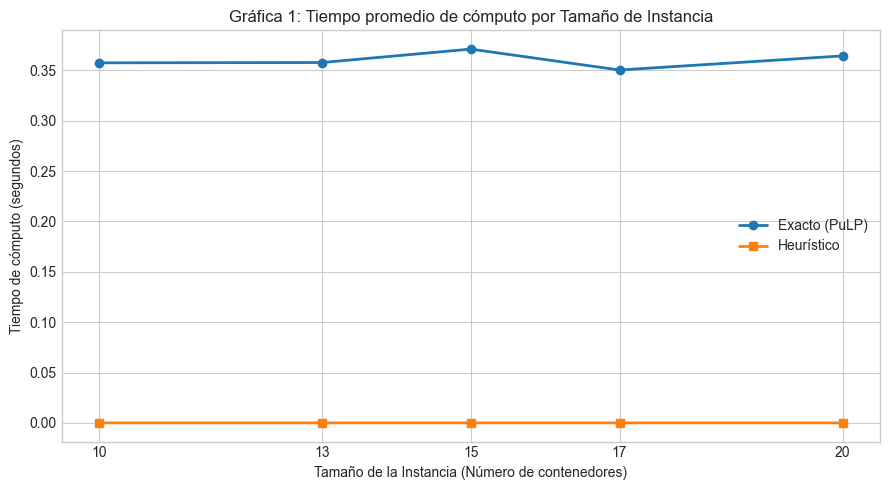

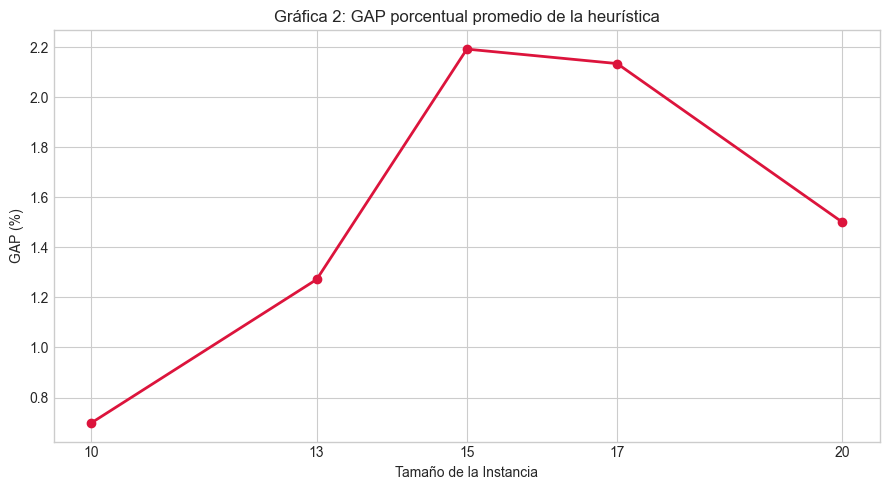

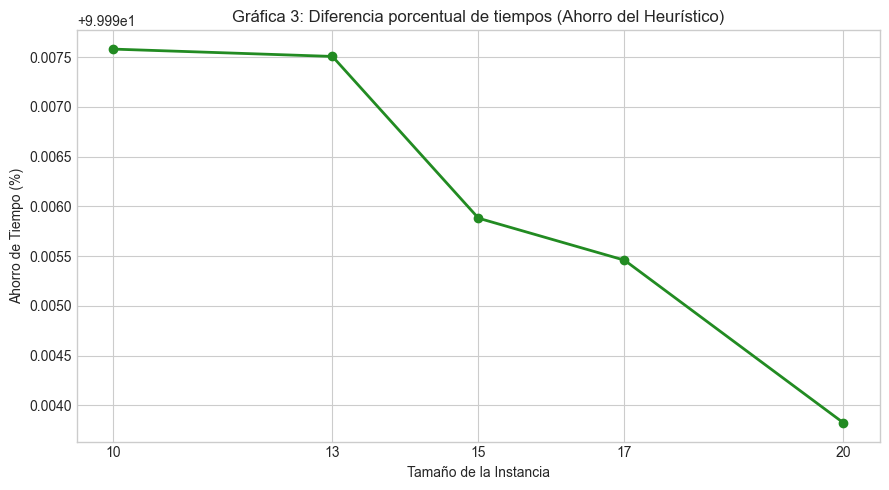

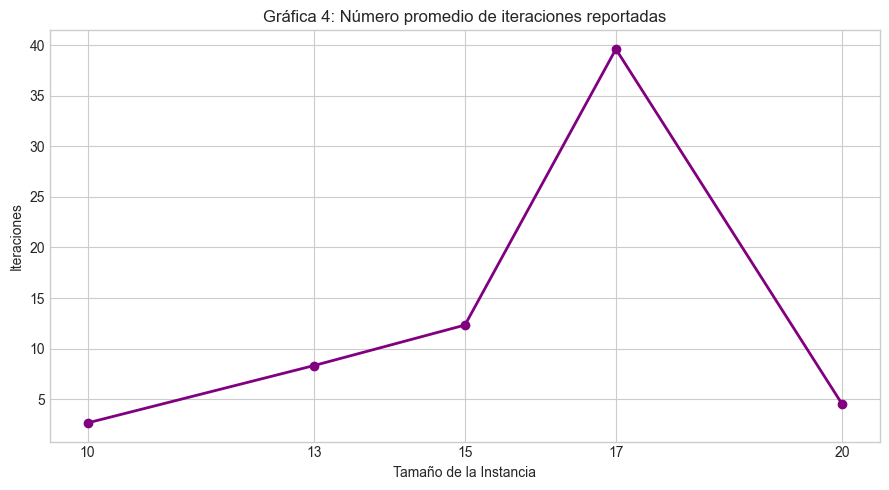

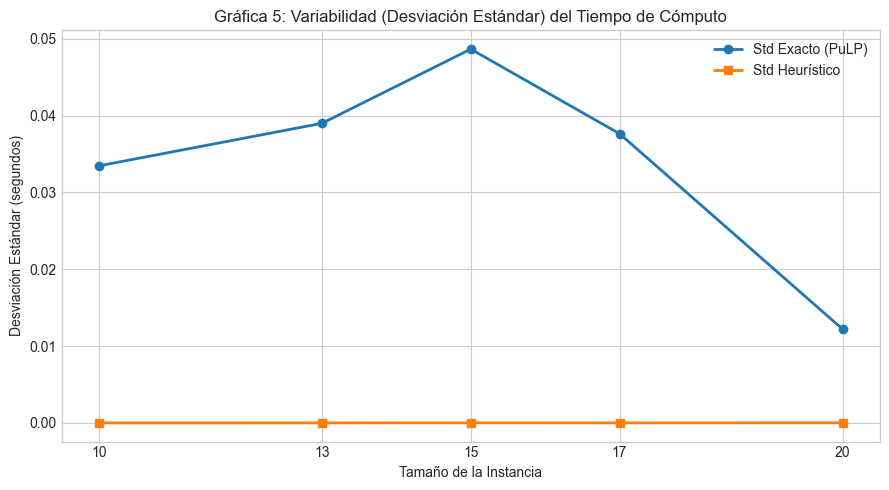

In [21]:
tamanos = agrupado['Tamaño']

plt.style.use('seaborn-v0_8-whitegrid')

# Gráfica 1: Tiempo promedio de cómputo
plt.figure(figsize=(9, 5))
plt.plot(tamanos, agrupado['Promedio_T_Exacto'], marker='o', linewidth=2, label='Exacto (PuLP)')
plt.plot(tamanos, agrupado['Promedio_T_Heuristico'], marker='s', linewidth=2, label='Heurístico')
plt.title("Gráfica 1: Tiempo promedio de cómputo por Tamaño de Instancia")
plt.xlabel("Tamaño de la Instancia (Número de contenedores)")
plt.ylabel("Tiempo de cómputo (segundos)")
plt.xticks(tamanos)
plt.legend()
plt.tight_layout()
plt.show()

# Gráfica 2: GAP porcentual promedio
plt.figure(figsize=(9, 5))
plt.plot(tamanos, agrupado['Promedio_GAP'], marker='o', color='crimson', linewidth=2)
plt.title("Gráfica 2: GAP porcentual promedio de la heurística")
plt.xlabel("Tamaño de la Instancia")
plt.ylabel("GAP (%)")
plt.xticks(tamanos)
plt.tight_layout()
plt.show()

# Gráfica 3: Diferencia porcentual promedio de los tiempos
plt.figure(figsize=(9, 5))
plt.plot(tamanos, agrupado['Promedio_Dif_Tiempo'], marker='o', color='forestgreen', linewidth=2)
plt.title("Gráfica 3: Diferencia porcentual de tiempos (Ahorro del Heurístico)")
plt.xlabel("Tamaño de la Instancia")
plt.ylabel("Ahorro de Tiempo (%)")
plt.xticks(tamanos)
plt.tight_layout()
plt.show()

# Gráfica 4: Número promedio de iteraciones
plt.figure(figsize=(9, 5))
plt.plot(tamanos, agrupado['Promedio_Iteraciones'], marker='o', color='purple', linewidth=2)
plt.title("Gráfica 4: Número promedio de iteraciones reportadas")
plt.xlabel("Tamaño de la Instancia")
plt.ylabel("Iteraciones")
plt.xticks(tamanos)
plt.tight_layout()
plt.show()

# Gráfica 5: Desviación estándar del tiempo de cómputo
plt.figure(figsize=(9, 5))
plt.plot(tamanos, agrupado['Std_T_Exacto'], marker='o', linewidth=2, label='Std Exacto (PuLP)')
plt.plot(tamanos, agrupado['Std_T_Heuristico'], marker='s', linewidth=2, label='Std Heurístico')
plt.title("Gráfica 5: Variabilidad (Desviación Estándar) del Tiempo de Cómputo")
plt.xlabel("Tamaño de la Instancia")
plt.ylabel("Desviación Estándar (segundos)")
plt.xticks(tamanos)
plt.legend()
plt.tight_layout()
plt.show()

## Primera implementación del heurístico

In [23]:
import time

Capacidad_Maxima = 700
Pesos = [100, 155, 50, 112, 70, 80, 60, 118, 110, 55]
Beneficios = [1741, 1622, 1016, 1264, 1305, 1389, 1797, 1330, 1559, 1578]

inicio = time.perf_counter() # tiempo computacional

# Cada contenedor con su peso y beneficio
contenedores = list(zip(Pesos, Beneficios))

# Ordenar los beneficios de mayor a menor
contenedores_ord = sorted(contenedores, key=lambda x: x[1], reverse=True)

Capacidad_disp = 700
contenedores_mochila = []
Beneficio_Total = 0

for contenedor in contenedores_ord:
    peso, beneficio = contenedor
    if Capacidad_disp >= peso:
        contenedores_mochila.append(contenedor)
        Capacidad_disp -= peso
        Beneficio_Total += beneficio * peso

fin = time.perf_counter()
tiempo_computacional = fin - inicio

print(contenedores_mochila)
print("Beneficio Total:", Beneficio_Total)
print(f"Tiempo computacional: {tiempo_computacional:.8f} segundos")

[(60, 1797), (100, 1741), (155, 1622), (55, 1578), (110, 1559), (80, 1389), (118, 1330)]
Beneficio Total: 1059670
Tiempo computacional: 0.00019770 segundos
